<a href="https://colab.research.google.com/github/J0n4ta/Trabalhos-Universit-rios-e-Projetos-Pessoais/blob/main/Classifica%C3%A7%C3%A3o_de_numeros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports


In [ ]:
import torch
import torch.utils
import torch.utils.data
import torchvision
import torchvision.transforms as transformers
from matplotlib import pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,recall_score, f1_score, precision_score
import seaborn as sns
import numpy as np

# Carregando DataSet

In [ ]:
transform = transformers.Compose([transformers.ToTensor(), transformers.Normalize((0.5, ),(0.5, ))])

train_dataset = torchvision.datasets.MNIST(
    root= "./data", transform=transform, train=True, download=True
)

train_dataset = torchvision.datasets.MNIST(
    root= "./data", transform=transform, train=False, download=True
)

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9.91M/9.91M [00:00<00:00, 38.6MB/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28.9k/28.9k [00:00<00:00, 1.26MB/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1.65M/1.65M [00:00<00:00, 9.29MB/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4.54k/4.54k [00:00<00:00, 4.99MB/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



# Separando dados de teste em "Caixas"(batchs) e embaralhando(Shuffle)

In [ ]:
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset, batch_size=32, shuffle=True
)

test_loader= torch.utils.data.DataLoader(
    dataset=train_dataset, batch_size=32, shuffle=False
)

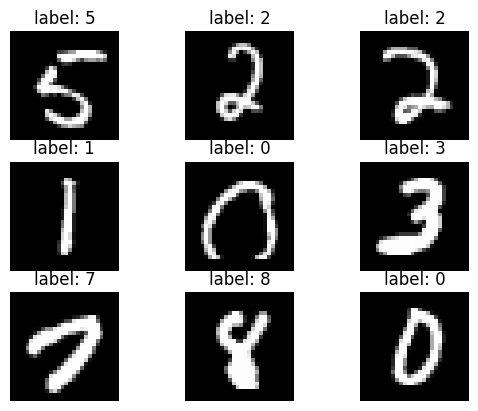

In [ ]:
examples = iter(train_loader)
images, labels = next(examples)

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i][0], cmap="gray")
    plt.title(f"label: {labels[i].item()}")
    plt.axis("off")
plt.show()

In [ ]:
class NeuralNet(nn.Module):
    def __init__(self):
        super(NeuralNet, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


In [ ]:
model = NeuralNet()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
num_epochs = 5
for epoch in range(num_epochs):
    for images, labels in train_loader:
        optimizer.zero_grad()

        outpputs = model(images)

        loss = criterion(outpputs, labels)

        loss.backward()

        optimizer.step()

    print(f"Epoch: [{epoch+1}{num_epochs}]\nLoss: {loss.item():.4f}")

Epoch: [15]
Loss: 0.1280
Epoch: [25]
Loss: 0.4858
Epoch: [35]
Loss: 0.2264
Epoch: [45]
Loss: 0.1621
Epoch: [55]
Loss: 0.4732


In [ ]:
model.eval()
all_preds=[]
all_labels=[]

with torch.no_grad():
    for images, labels in test_loader:
        output = model(images)
        _, predicted = torch.max(output, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [ ]:
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average="weighted")
recall = recall_score(all_labels, all_preds, average="weighted")
f1 = f1_score(all_labels, all_preds, average="weighted")

print(f"Accuracy: {accuracy:.5f}")
print(f"Precision: {precision:.5f}")
print(f"Recall: {recall:.5f}")
print(f"f1: {f1:.5f}")

Accuracy: 0.93280
Precision: 0.93668
Recall: 0.93280
f1: 0.93277


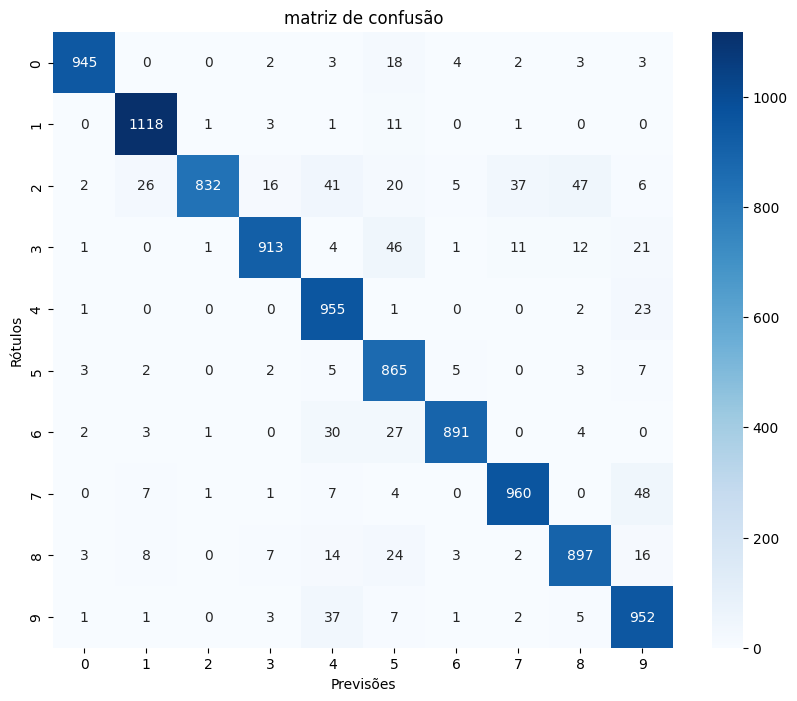

In [ ]:
conf_matrix = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))

sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=np.arange(10), yticklabels=np.arange(10))

plt.xlabel("Previsões")
plt.ylabel("Rótulos")
plt.title("matriz de confusão")
plt.show()

In [ ]:
examples = iter(test_loader)

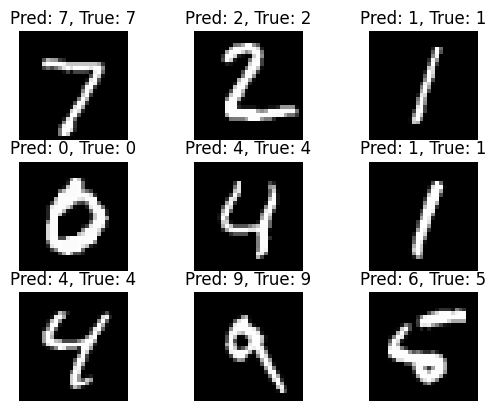

In [ ]:
images, labels = next(examples)

outputs = model(images)

_, predicted = torch.max(outputs, 1)

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i][0], cmap="gray")
    plt.title(f"Pred: {predicted[i].item()}, True: {labels[i].item()}")
    plt.axis("off")
plt.show()